# 02 — Model and backtest

**Setup:** forecast the 24 hourly prices of day D on the morning of D-1, using only information available then (`src/features.py`).
**Model:** LightGBM with an L1 (MAE) objective, predictions clipped to [0, recent cap].
**Validation:** walk-forward backtest over the last 12 months: each month is forecast by a model trained only on data before that month (`src/train.py`).

Run `python src/features.py` and `python src/train.py` first.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
R = ROOT / "reports"
bt = pd.read_parquet(R / "backtest_predictions.parquet")
metrics = pd.read_csv(R / "metrics.csv", index_col=0)
by_month = pd.read_csv(R / "metrics_by_month.csv", index_col=0, parse_dates=True)
importance = pd.read_csv(R / "feature_importance.csv", index_col=0)["share_of_gain"]
print(f"Backtest: {bt.index.min().date()} -> {bt.index.max().date()} ({len(bt):,} hours)")
metrics.round(1)

Backtest: 2025-11-03 -> 2026-11-02 (8,760 hours)


,MAE,RMSE,MAE_pct_of_mean_price
lightgbm,388.2,558.8,17.6
naive_d1_d7_avg,478.3,696.7,21.7
naive_d1,520.0,807.0,23.6
naive_d7,606.0,907.9,27.5


In [2]:
imp = 1 - metrics.loc["lightgbm", "MAE"] / metrics.loc["naive_d1_d7_avg", "MAE"]
print(f"LightGBM MAE: {metrics.loc['lightgbm', 'MAE']:.0f} TL/MWh vs best naive {metrics.loc['naive_d1_d7_avg', 'MAE']:.0f} -> {imp:.1%} better")

LightGBM MAE: 388 TL/MWh vs best naive 478 -> 18.8% better


## 1. Error month by month

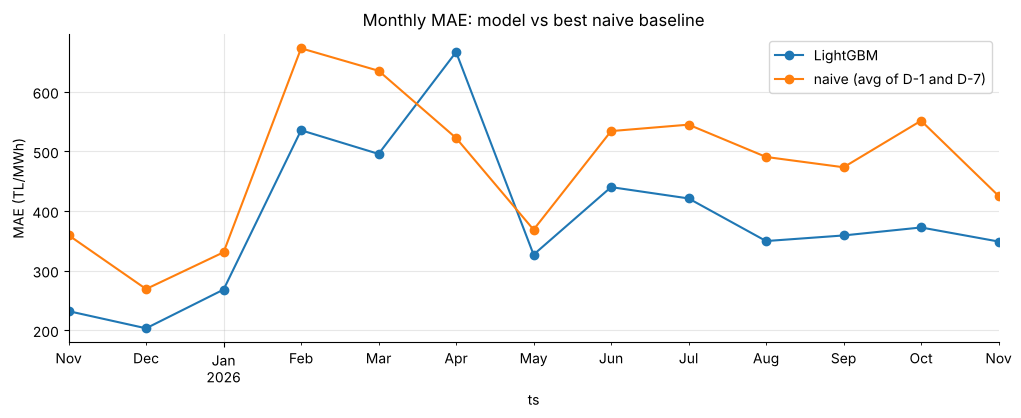

,lightgbm,naive_d1_d7_avg,improvement_pct
ts,,,
2025-11-30,232.0,359.4,35.4
2025-12-31,203.2,269.1,24.5
2026-01-31,268.2,330.8,18.9
2026-02-28,535.5,673.0,20.4
2026-03-31,495.8,635.3,22.0
2026-04-30,666.7,522.5,-27.6
2026-05-31,326.8,368.7,11.4
2026-06-30,440.1,534.1,17.6
2026-07-31,421.1,544.9,22.7


In [3]:
ax = by_month[["lightgbm", "naive_d1_d7_avg"]].plot(marker="o")
ax.set_ylabel("MAE (TL/MWh)"); ax.set_title("Monthly MAE: model vs best naive baseline")
ax.legend(["LightGBM", "naive (avg of D-1 and D-7)"]); plt.show()
by_month[["lightgbm", "naive_d1_d7_avg"]].assign(
    improvement_pct=lambda d: (1 - d.lightgbm / d.naive_d1_d7_avg) * 100).round(1)

## 2. What the forecasts look like

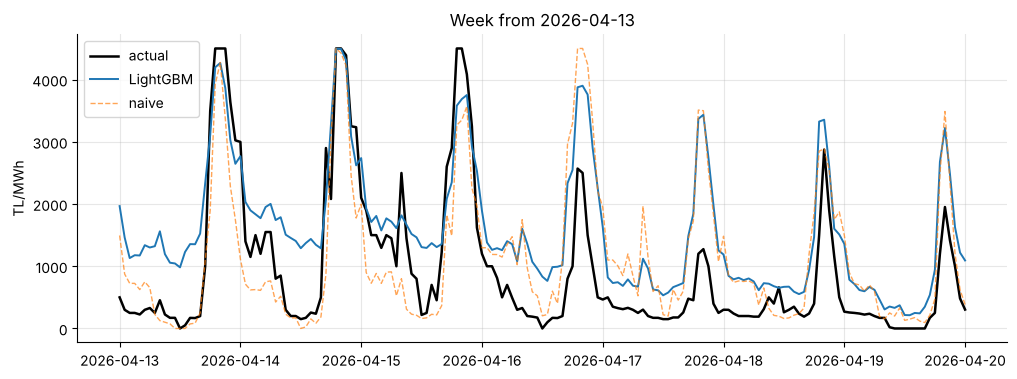

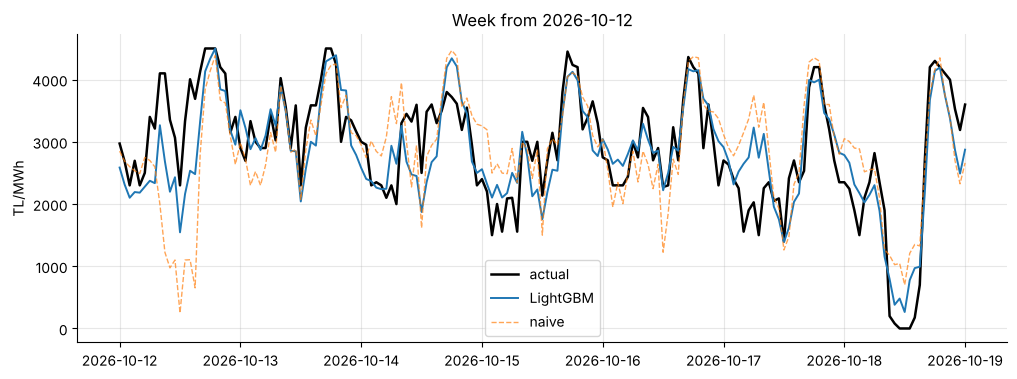

In [4]:
def plot_week(start):
    w = bt.loc[start: pd.Timestamp(start) + pd.Timedelta(days=7)]
    fig, ax = plt.subplots()
    ax.plot(w.index, w["actual"], label="actual", color="black", lw=1.8)
    ax.plot(w.index, w["lightgbm"], label="LightGBM", lw=1.4)
    ax.plot(w.index, w["naive_d1_d7_avg"], label="naive", lw=1, ls="--", alpha=0.7)
    ax.set_ylabel("TL/MWh"); ax.set_title(f"Week from {start}"); ax.legend(); plt.show()

plot_week("2026-04-13")   # spring: solar + hydro, zero-price middays
plot_week("2026-10-12")   # autumn: more 'normal' week

## 3. Error by hour of day

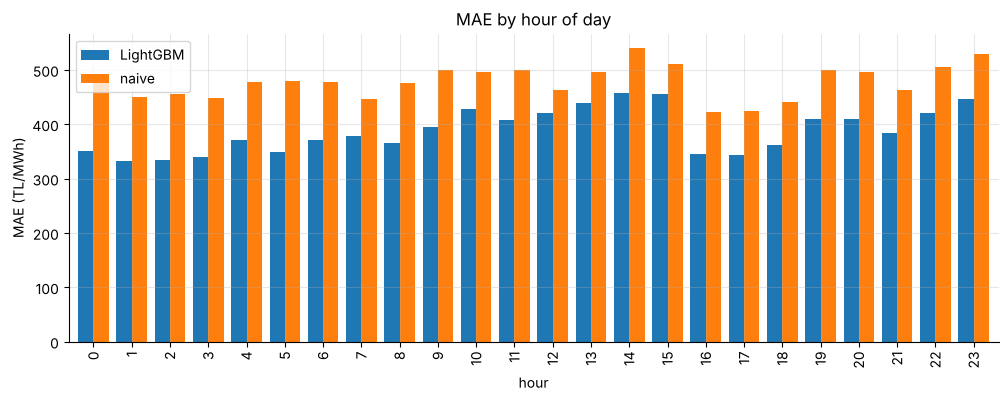

In [5]:
err = bt[["lightgbm", "naive_d1_d7_avg"]].sub(bt["actual"], axis=0).abs()
err.groupby(bt.index.hour).mean().plot(kind="bar", width=0.8)
plt.xlabel("hour"); plt.ylabel("MAE (TL/MWh)"); plt.title("MAE by hour of day")
plt.legend(["LightGBM", "naive"]); plt.show()

## 4. Which features matter?

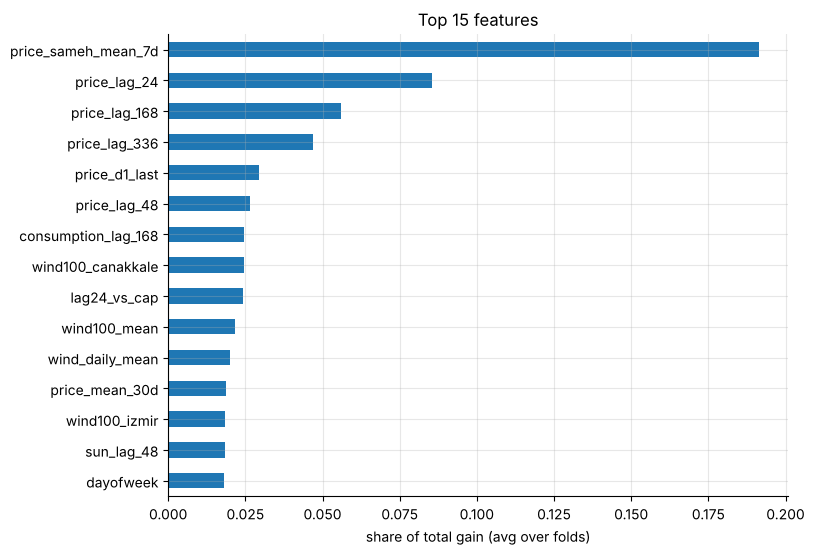

In [6]:
top = importance.head(15)[::-1]
top.plot(kind="barh", figsize=(8, 6))
plt.xlabel("share of total gain (avg over folds)"); plt.title("Top 15 features"); plt.show()

## 5. Biggest misses

The days where the model was most wrong are the most interesting part of the analysis — they show what the model *can't* see.

In [7]:
daily_err = (bt["lightgbm"] - bt["actual"]).abs().resample("D").mean()
worst = daily_err.sort_values(ascending=False).head(8)
summary = pd.DataFrame({
    "MAE": worst.round(0),
    "actual_mean": bt["actual"].resample("D").mean().loc[worst.index].round(0),
    "forecast_mean": bt["lightgbm"].resample("D").mean().loc[worst.index].round(0),
    "weekday": worst.index.day_name(),
})
summary

,MAE,actual_mean,forecast_mean,weekday
ts,,,,
2026-02-15,1199.0,301.0,1500.0,Sunday
2026-07-01,1128.0,3288.0,2240.0,Wednesday
2026-04-07,1100.0,1181.0,2103.0,Tuesday
2026-02-16,1033.0,1159.0,2118.0,Monday
2026-04-16,1028.0,725.0,1753.0,Thursday
2026-03-27,1005.0,871.0,1735.0,Friday
2026-04-27,1003.0,341.0,1343.0,Monday
2026-06-10,978.0,1935.0,956.0,Wednesday


## 6. Takeaways

**Result.** Over the last 12 months the model's MAE is about **388 TL/MWh (17.6% of the mean price)**, versus 478 TL/MWh for the best naive baseline: roughly a **19% improvement**. It beats the baseline in 12 of 13 months, by 20–35% in most of them, and at every hour of the day.

**Where it fails: April 2026.** April is the one month where the model is clearly *worse* than the baseline (MAE ≈667 vs ≈523). The weekly plot shows why: during the spring collapse, night and midday prices fell to a few hundred TL or zero, but the model kept forecasting 1,000–2,000 TL. Prices had never stayed that low for so long in the training data (2022–2025), so the model had no examples of this regime and stayed anchored to the old price levels. The naive baseline simply copies yesterday and adapts immediately. Most of the biggest-miss days (Feb 15–16, Mar 27, Apr 7, 16, 27) follow the same pattern: very low actual prices, much higher forecasts.

**The opposite miss.** On a few days (Jul 1, Jun 10) the price jumped well above recent levels and the model was too low. Sudden shifts in either direction are hard to see from history alone.

**Most important features.** Recent prices dominate: the same-hour average over the last 7 days, yesterday's price, and the prices one and two weeks ago. After that come wind speed (Çanakkale, İzmir), demand a week ago, the price relative to the cap, and the day of the week.

**Weather caveat.** The backtest uses realised weather as a stand-in for the weather forecast, which is slightly optimistic. Without any weather features the model still reaches an MAE of about 398 TL/MWh, so the true production performance should lie between 388 and 398: still a ~17–19% improvement.

**Next steps.**
- Handle regime shifts: weight recent data more heavily, or blend with the naive forecast when prices move far from historical levels.
- Add hydro inputs (dam reservoir levels, river flows) that explain the spring collapse.
- Use real historical weather forecasts (Open-Meteo Historical Forecast API) instead of realised weather.